# RNN 순환 신경망 실습

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SuminHan/book-ml/blob/main/slides/v2/ml1/week11/rnn/lab/rnn.ipynb)

단어 (글자) 를 하나씩 읽으며 메모를 고쳐 쓴다: $\mathbf{h}_t = \tanh(W_x \mathbf{x}_t + W_h \mathbf{h}_{t-1} + \mathbf{b})$.

- **파트 1**: numpy 로 RNN 한 칸 → 손 계산, 두 문장의 메모
- **파트 2**: PyTorch `nn.RNN` 글자 단위 언어 모델 (셰익스피어)
- **파트 3**: 글 써 보기 · 온도

`None` 으로 비워 둔 `TODO` 줄을 채우고 셀을 차례로 실행하세요. 파트 2 는 몇 분 걸린다.

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import torch, torch.nn as nn

## 파트 1. RNN 한 칸

슬라이드의 손 계산: 메모 한 칸, $w_x = 1$, $w_h = 0.5$, 입력 1, 0, 1 → 0.762, 0.363, 0.828.

In [ ]:
def rnn_step(x, h, Wx, Wh, b):
    return None  # TODO: one RNN step

def run_rnn(xs, Wx, Wh, b):
    h = np.zeros(Wh.shape[0]); hs = []
    for x in xs:
        h = rnn_step(x, h, Wx, Wh, b); hs.append(h)
    return hs

hs = run_rnn([np.array([1.0]), np.array([0.0]), np.array([1.0])], np.array([[1.0]]), np.array([[0.5]]), np.zeros(1))
print([round(float(h[0]), 3) for h in hs])

# Same 4-cell RNN as the slides (random weights, seed 11): word order changes the final memory
rng = np.random.default_rng(11)
emb = {w: rng.normal(0, 1, 4) for w in ("dog", "bites", "man")}
Wx, Wh = rng.normal(0, 0.8, (4, 4)), rng.normal(0, 0.8, (4, 4))
for sentence in [["dog", "bites", "man"], ["man", "bites", "dog"]]:
    final = run_rnn([emb[w] for w in sentence], Wx, Wh, np.zeros(4))[-1]
    bag = sum(emb[w] for w in sentence)
    print(" ".join(sentence), " final memory:", final.round(2), "  sum of words:", bag.round(2))

**예상 결과**

```
[0.762, 0.363, 0.828]
dog bites man  final memory: [ 0.5   0.66  0.93 -0.27]   sum of words: [ 0.48 -1.01  3.36 -0.66]
man bites dog  final memory: [-0.55 -0.37 -0.84 -0.71]   sum of words: [ 0.48 -1.01  3.36 -0.66]
```

## 파트 2. 글자 단위 언어 모델

셰익스피어 희곡 약 111만 글자. 길이 64 조각에서 매 칸의 **다음 글자**를 맞힌다.

In [ ]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
os.makedirs("data", exist_ok=True)
if not os.path.exists("data/shakespeare.txt"):
    import urllib.request; urllib.request.urlretrieve(url, "data/shakespeare.txt")
text = open("data/shakespeare.txt").read()
chars = sorted(set(text)); stoi = {c: i for i, c in enumerate(chars)}
data = torch.tensor([stoi[c] for c in text])
print(len(text), "characters,", len(chars), "distinct;  ln(V) =", round(np.log(len(chars)), 2))
print(text[:200])

**예상 결과**

```
1115394 characters, 65 distinct;  ln(V) = 4.17
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you
```

In [ ]:
class CharRNN(nn.Module):
    def __init__(self, vocab, hidden=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, hidden)
        self.rnn = nn.RNN(hidden, hidden, batch_first=True)
        self.out = nn.Linear(hidden, vocab)

    def forward(self, x, h=None):
        o, h = self.rnn(self.emb(x), h)
        return self.out(o), h

def get_batch(data, seq=64, batch=64, gen=None):
    ix = torch.randint(0, len(data) - seq - 1, (batch,), generator=gen)
    x = torch.stack([data[i:i + seq] for i in ix])
    y = None  # TODO: the next character at every position
    return x, y

torch.manual_seed(0)
model = CharRNN(len(chars)); opt = torch.optim.Adam(model.parameters(), 3e-3); gen = torch.Generator().manual_seed(0)
losses = []
for step in range(1000):
    x, y = get_batch(data, gen=gen)
    logits, _ = model(x)
    loss = nn.functional.cross_entropy(logits.reshape(-1, len(chars)), y.reshape(-1))
    opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 1.0); opt.step()
    losses.append(loss.item())
    if step % 200 == 0:
        print(f"step {step}: loss {loss.item():.2f}")
plt.plot(losses); plt.xlabel("step"); plt.ylabel("loss"); plt.show()

**예상 결과**

```
step 0: loss 4.18
step 200: loss 1.91
step 400: loss 1.78
step 600: loss 1.73
step 800: loss 1.68
```

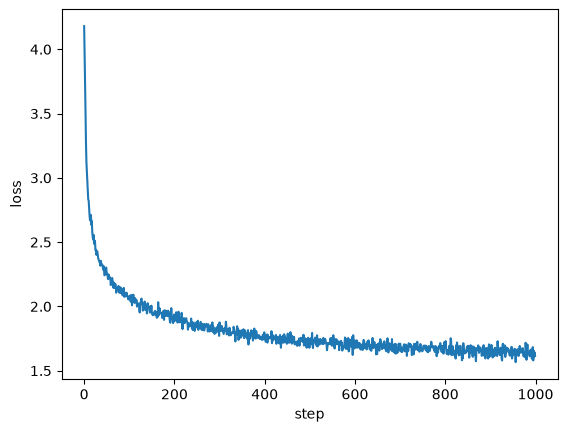

## 파트 3. 글 써 보기

시작 글자를 넣고, 나온 확률대로 다음 글자를 뽑아 다시 넣는다. 온도 $T$: 확률을 $\text{softmax}(z / T)$ 로. 작으면 무난, 크면 엉뚱.

In [ ]:
def generate(model, start, n=300, temperature=0.8, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.tensor([[stoi[c] for c in start]]); out = start; h = None
    with torch.no_grad():
        logits, h = model(x, h)
        for _ in range(n):
            p = None  # TODO: probabilities with temperature
            c = torch.multinomial(p, 1, generator=g).item()
            out += chars[c]
            logits, h = model(torch.tensor([[c]]), h)
    return out

for T in [0.5, 1.0, 1.5]:
    print(f"--- temperature {T} ---"); print(generate(model, "ROMEO:", 200, T)); print()

**예상 결과**

```
--- temperature 0.5 ---
ROMEO:
Why make the contented can excears in the strend hour with the bear change of the spires to him some so your way, and come are by a not me fortune the store a man in his gods, sir, the will thee.

SI

--- temperature 1.0 ---
ROMEO:
Why mome kiss! Then, ouch mean's comn I tost, greconsedy his tweetre his death being some shall stants, your wake excheet is earler none have too well you for me I see that the contring.

FRISBARGSHE

--- temperature 1.5 ---
ROMEO:
Pore his kiss! Thee, o'ca nexhay youd Igelse, greconues, his tweetre hish Sombs
Ahell! Take him; that's your wake exaccessiay thour none haffry!
He paly one ai'd Iire?

... (2줄 더)
```

**확인 질문**
1. 파트 1 에서 두 문장의 '단어 합' 은 같은데 마지막 메모는 다르다. 왜인가?
2. 파트 2 의 첫 손실이 ln 65 근처인 이유는?
3. 파트 3 에서 온도를 0.1 로 하면 어떤 글이 나오나? 왜 같은 말을 되풀이하기 쉬울까?
4. (도전) 은닉 크기를 128 → 256 으로, 또는 `nn.RNN` 을 `nn.LSTM` 으로 바꾸면 손실이 어떻게 달라지나? (다음 시간)

데이터 출처: Tiny Shakespeare, Andrej Karpathy char-rnn (2015).